# Feature importance and SHAP

This notebook examines what the tuned remaining useful life (RUL) models rely on. For Random Forest and XGBoost it compares impurity-based importance with permutation importance on held-out engines, and it explains the selected XGBoost model with SHAP values. For Elastic Net it examines which standardised coefficients the L1 penalty sets to zero. The results are then compared with the sensors that the exploratory analysis identified as degrading. Only the FD001 training trajectories are used.

## Setup

Each model uses its selected configuration on the engineered feature set (142 columns), read from `results/best_params.json`, and is trained on RUL capped at 125 cycles. The models explained by impurity importance, SHAP values, and coefficients are fitted on all 100 training engines, with the feature statistics (regime normalisation and the health-index model) also fitted on all of them.

The engineered columns are strongly correlated: each sensor contributes its raw reading and a rolling mean, standard deviation, and slope over three windows, ten columns in all. Importance spread over ten near-duplicate columns is hard to read and, for permutation importance, understated (see below). Results are therefore also aggregated into 16 groups: one per sensor, plus `cycle` and `health_index`. A column belongs to the sensor it is computed from, so `s_2`, `s_2_mean_5`, `s_2_std_10`, and `s_2_slope_20` all belong to `s_2`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from rul.data import USEFUL_SENSORS, add_rul, load_train_fd
from rul.explain import group_permutation_importance, sensor_group
from rul.features import feature_groups, make_features
from rul.models import build_model
from rul.split import engine_folds

RUL_CAP = 125
SEED = 42
WINDOWS = (5, 10, 20)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 220})


def save(fig, name):
    """Save a figure under figures/explain_<name>.png."""
    fig.savefig(ROOT / "figures" / f"explain_{name}.png", bbox_inches="tight", facecolor="white")

In [2]:
train = add_rul(load_train_fd("FD001"))
train["rul"] = train["rul"].clip(upper=RUL_CAP)

groups = feature_groups(USEFUL_SENSORS, WINDOWS)
FEATURES = groups["raw"] + groups["rolling"] + groups["slope"] + groups["health"]
best_params = json.loads((ROOT / "results" / "best_params.json").read_text())["models"]
PARALLEL = {"random_forest": {"n_jobs": -1}, "xgboost": {"n_jobs": -1}, "elastic_net": {}}


def fit(name, data):
    """Fit a model with its selected engineered-feature configuration."""
    params = best_params[f"{name}/engineered"]["params"]
    return build_model(name, **params, **PARALLEL[name]).fit(data[FEATURES], data["rul"])


# The explained models are fitted on all 100 training engines, features included.
full, full_scaler = make_features(train, USEFUL_SENSORS, WINDOWS)
models = {name: fit(name, full) for name in ("elastic_net", "random_forest", "xgboost")}
GROUPS = pd.Index(FEATURES).map(sensor_group)
print(f"{len(FEATURES)} features in {GROUPS.nunique()} sensor groups")
pd.Series(GROUPS).value_counts().rename("columns").to_frame().T

142 features in 16 sensor groups


,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21,cycle,health_index
columns,10,10,10,10,10,10,10,10,10,10,10,10,10,10,1,1


## Impurity importance

Impurity importance credits each feature with the reduction in training loss produced by the splits that use it. For Random Forest this is the mean decrease in squared error (variance) per split, weighted by the number of rows reaching the split and averaged over trees. For XGBoost the comparable quantity is `total_gain`: the total reduction in the regularised training loss over all splits on the feature. XGBoost's default `gain` is the *average* gain per split, which favours features used in a few high-gain splits and cannot be summed over a group, so `total_gain` is requested explicitly. Both are normalised to sum to one per model.

Impurity importance is computed on training data and is a by-product of how the trees were grown. When several features carry the same information, the credit is shared between them in whatever way the tree-building happened to choose, so a feature can receive little credit while being useful.

In [3]:
impurity = pd.DataFrame({
    "random_forest": models["random_forest"].feature_importances_,
    "xgboost": models["xgboost"].get_booster().get_score(importance_type="total_gain"),
}, index=FEATURES).fillna(0)
impurity = impurity / impurity.sum()  # share of each model's total impurity reduction
impurity_by_group = impurity.groupby(GROUPS).sum().sort_values("xgboost", ascending=False)

print("Top columns:")
display(impurity.sort_values("xgboost", ascending=False).head(10))
impurity_by_group

Top columns:


,random_forest,xgboost
health_index,0.363,0.575
cycle,0.080,0.095
s_4_mean_10,0.160,0.076
s_4_mean_5,0.096,0.054
s_15_mean_10,0.017,0.035
s_2_mean_10,0.012,0.020
s_11_mean_5,0.011,0.010
s_11_slope_20,0.010,0.010
s_8_slope_20,0.009,0.009
s_14_slope_20,0.006,0.008


,random_forest,xgboost
health_index,0.363,0.575
s_4,0.263,0.136
cycle,0.080,0.095
s_15,0.029,0.046
s_2,0.019,0.026
s_11,0.103,0.023
s_14,0.020,0.019
s_9,0.032,0.017
s_8,0.015,0.012
s_13,0.011,0.011


## Permutation importance on held-out engines

Permutation importance measures how much a model's error rises when the link between one input and the target is broken by shuffling that input's values across rows. It is computed on engines the model did not see: for each of the five engine-grouped folds used in model selection, the model is refitted on the fold's training engines and the shuffling is done on its validation engines. The reported value is the increase in RMSE, averaged over five shuffles per fold and then over folds.

Shuffling a single column understates the importance of a sensor whose information is duplicated in other columns, because the model can recover it from the unshuffled copies. All columns of a group are therefore shuffled together, using the same row order, so the whole sensor is removed at once while the columns stay consistent with each other.

In [4]:
# Same folds as model selection; features are fitted on each fold's training engines.
permutation = {}
for fold, (train_idx, val_idx) in enumerate(engine_folds(train, n_splits=5)):
    fold_train, scaler = make_features(train.iloc[train_idx], USEFUL_SENSORS, WINDOWS)
    fold_val, _ = make_features(train.iloc[val_idx], USEFUL_SENSORS, WINDOWS, scaler=scaler)
    for name in ("random_forest", "xgboost"):
        permutation[(name, fold)] = group_permutation_importance(
            fit(name, fold_train), fold_val[FEATURES], fold_val["rul"], n_repeats=5,
            seed=SEED + fold)
permutation = pd.DataFrame(permutation)
perm_mean = permutation.T.groupby(level=0).mean().T
perm_std = permutation.T.groupby(level=0).std().T
perm_table = pd.concat({"mean": perm_mean, "std across folds": perm_std}, axis=1)
perm_table.sort_values(("mean", "xgboost"), ascending=False)

mean         std across folds        
             random_forest xgboost    random_forest xgboost
health_index         7.361  10.955            0.496   0.215
cycle                5.220   4.844            0.519   0.564
s_9                  1.449   1.049            0.300   0.089
s_15                 0.641   1.018            0.381   0.435
s_4                  1.618   0.889            0.685   0.315
s_2                  0.212   0.885            0.076   0.365
s_11                 1.400   0.835            0.234   0.146
s_14                 0.535   0.758            0.411   0.480
s_13                 0.298   0.718            0.077   0.192
s_8                  0.502   0.510            0.078   0.133
s_12                 0.389   0.492            0.040   0.097
s_7                  0.352   0.487            0.095   0.166
s_3                  0.129   0.280            0.079   0.167
s_20                 0.049   0.250            0.051   0.122
s_17                 0.116   0.193            0.037   0.075
s_21                 0.120   0.173            0.092   0.039

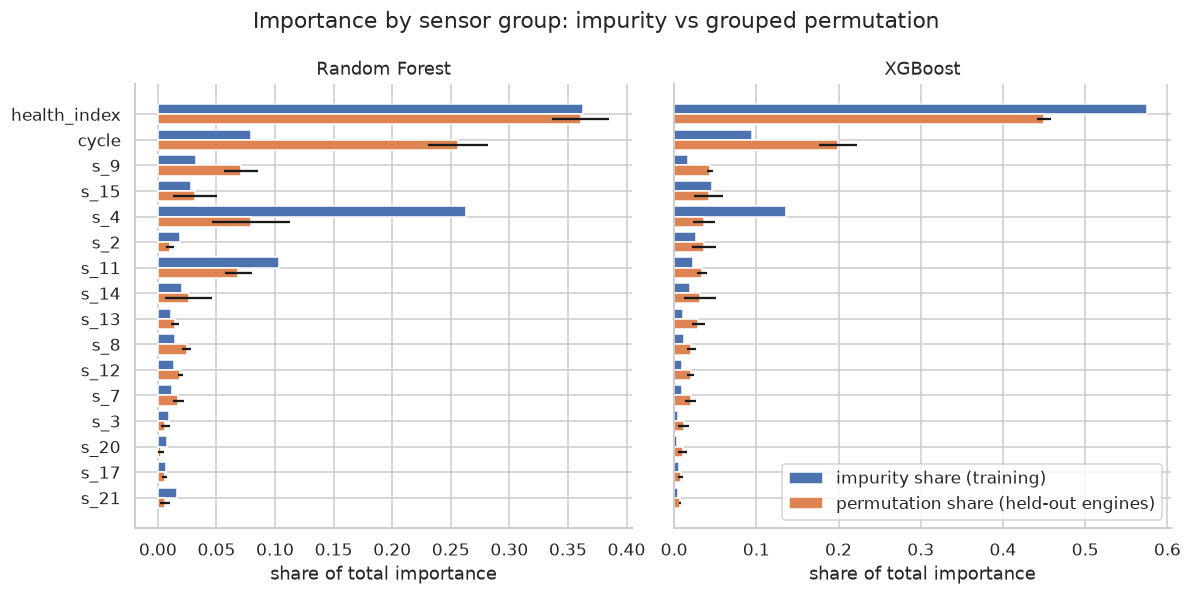

In [5]:
order = perm_mean.sort_values("xgboost").index
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
for ax, name, title in zip(axes, ("random_forest", "xgboost"), ("Random Forest", "XGBoost")):
    y = np.arange(len(order))
    ax.barh(y + 0.2, impurity_by_group.loc[order, name], 0.4, label="impurity share (training)")
    ax.barh(y - 0.2, perm_mean.loc[order, name] / perm_mean[name].sum(), 0.4,
            xerr=perm_std.loc[order, name] / perm_mean[name].sum(),
            label="permutation share (held-out engines)")
    ax.set_yticks(y, order)
    ax.set_title(title)
    ax.set_xlabel("share of total importance")
axes[1].legend(loc="lower right")
fig.suptitle("Importance by sensor group: impurity vs grouped permutation")
fig.tight_layout()
save(fig, "importance")

Both models depend most on `health_index` under either measure, and on held-out engines `cycle` comes second. Shuffling the health index on held-out engines raises XGBoost's RMSE by 10.95 cycles and Random Forest's by 7.36; shuffling `cycle` raises them by 4.84 and 5.22. No other group adds more than 1.62 cycles.

Below those two, impurity and permutation importance disagree. Impurity importance gives `s_4` 26% of Random Forest's training loss reduction and 14% of XGBoost's, but shuffling `s_4` on held-out engines costs only 1.62 and 0.89 cycles. `s_4` is strongly correlated with `s_11` and the other degrading sensors, and it is one of the inputs to the health index, so when it is shuffled the models recover most of its information from those columns. Impurity importance credits whichever correlated feature a split happened to choose; permutation importance measures what the model loses when the feature's information is no longer available from that group. `cycle` shows the opposite pattern: 8 to 10% of the impurity reduction but 20 to 26% of the permutation importance, because no other input carries the engine's age, so nothing can stand in for it when it is shuffled.

Impurity importance describes how the trees were grown on the training rows, including any splits that fit noise. Permutation importance on held-out engines measures how much the model's accuracy on unseen engines depends on each input.

## SHAP values for XGBoost

A SHAP value is the contribution of one feature to one prediction, measured relative to the model's average prediction. For each row the contributions add up exactly: base value + sum of the row's SHAP values = prediction, where the base value is the mean prediction over the training data. Each contribution is the feature's average marginal effect on the prediction over all orders in which features could be added (the Shapley value from cooperative game theory). `shap.TreeExplainer` computes these values exactly for tree ensembles.

The values below explain the XGBoost model fitted on all training engines, on a seeded sample of 2,000 training rows.

Base value 86.83; max additivity gap 1.4e-04 cycles


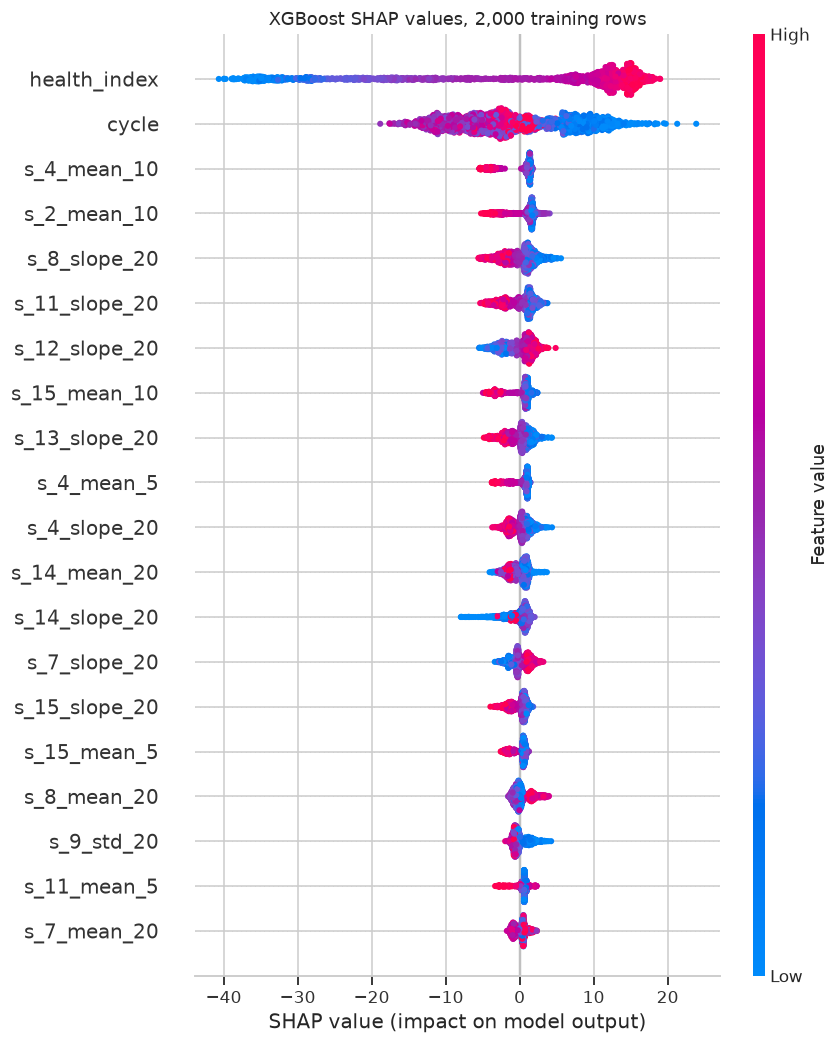

In [6]:
xgb = models["xgboost"]
sample = full[FEATURES].sample(2000, random_state=SEED)
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(sample)

# Additivity: base value plus the row's SHAP values reproduces the model's prediction.
reconstructed = explainer.expected_value + shap_values.sum(axis=1)
max_gap = np.abs(reconstructed - xgb.predict(sample)).max()
assert max_gap < 1e-2, max_gap
print(f"Base value {float(explainer.expected_value):.2f}; max additivity gap {max_gap:.1e} cycles")

shap.summary_plot(shap_values, sample, max_display=20, show=False)
fig = plt.gcf()
fig.axes[0].set_title("XGBoost SHAP values, 2,000 training rows")
save(fig, "shap_summary")
plt.show()

In [7]:
# SHAP values add, so a sensor's contribution to one prediction is the sum over its columns.
shap_by_group = pd.DataFrame(shap_values, columns=FEATURES).T.groupby(GROUPS).sum().T
shap_group_mean = shap_by_group.abs().mean().sort_values(ascending=False).rename("mean |SHAP|")
shap_group_mean.to_frame()

,mean |SHAP|
health_index,15.262
cycle,6.777
s_4,3.443
s_15,2.885
s_2,2.846
s_14,2.324
s_11,2.242
s_9,2.108
s_13,1.906
s_8,1.828


The additivity check passes: base value plus SHAP values differs from the prediction by at most 1.4 × 10⁻⁴ cycles. The base value, 86.83 cycles, is the model's mean prediction on the training rows, and each point in the summary plot shows how far one feature moved one prediction away from it. The plot shows the 20 columns with the largest mean absolute SHAP value; colour is the feature's value.

The health index dominates. A low health index (blue) lowers the prediction by up to about 40 cycles, and a high one raises it by up to about 20. `cycle` acts in the opposite direction: early cycles push predictions up and late cycles push them down. The sensor columns have smaller effects, and their directions agree with the degradation trends: high recent means and steep positive slopes of `s_4`, `s_2`, `s_11`, and `s_15`, which rise towards failure, lower the predicted RUL, while for `s_12` and `s_7`, which fall towards failure, low (negative) slopes lower it. Every slope among the top 20 columns uses the 20-cycle window, consistent with the longest window giving the least noisy estimate of the trend.

SHAP values add, so a sensor's contribution to a prediction is the sum of the SHAP values of its columns. Averaged over the sample, the health index contributes 15.3 cycles in absolute value, `cycle` 6.8, and the leading sensors `s_4`, `s_15`, and `s_2` between 2.8 and 3.4 each.

## Elastic Net coefficients

The Elastic Net model standardises every input before fitting, so its coefficients are in cycles of RUL per standard deviation of the input and their magnitudes are comparable. The L1 part of the penalty can set coefficients exactly to zero.

In [8]:
en = models["elastic_net"].named_steps["model"]
print(f"alpha={en.alpha}, l1_ratio={en.l1_ratio}")
coef = pd.Series(en.coef_, index=FEATURES, name="coefficient")
family = pd.Index(FEATURES).map(
    lambda c: next((f for f in ("mean", "std", "slope") if f"_{f}_" in c),
                   "health index" if c == "health_index" else "raw"))
zero = coef == 0
print(f"{zero.sum()} of {len(coef)} coefficients are exactly zero")
pd.DataFrame({"columns": coef.groupby(family).size(), "zero": zero.groupby(family).sum()})

alpha=0.001, l1_ratio=0.8
0 of 142 coefficients are exactly zero


,columns,zero
health index,1,0
mean,42,0
raw,15,0
slope,42,0
std,42,0


In [9]:
print("Zero coefficients:", ", ".join(coef.index[zero]) or "none")
coef.loc[coef.abs().sort_values(ascending=False).index].head(10).to_frame()

Zero coefficients: none


,coefficient
health_index,40.313
s_11_mean_20,22.475
s_8_mean_20,21.352
s_13_mean_20,21.218
s_12_mean_20,-21.118
s_11_mean_10,-20.111
s_12_mean_10,16.265
s_8_mean_10,-15.680
s_7_mean_20,-14.078
s_7_mean_10,13.846


In [10]:
# Strengthening a pure L1 penalty shows which columns the linear model can do without.
nonzero = {}
for alpha in (0.001, 0.01, 0.1, 0.3, 1.0):
    lasso = build_model("elastic_net", alpha=alpha, l1_ratio=1.0, max_iter=100_000,
                        precompute=True).fit(full[FEATURES], full["rul"])
    nonzero[alpha] = pd.Series(lasso.named_steps["model"].coef_ != 0, index=FEATURES)
nonzero = pd.DataFrame(nonzero).rename_axis(columns="alpha")
for alpha in (0.1, 1.0):
    kept = nonzero.index[nonzero[alpha]]
    print(f"alpha={alpha}: {len(kept)} columns kept from {kept.map(sensor_group).nunique()} groups:",
          ", ".join(kept))
nonzero.groupby(family).sum().rename_axis("non-zero columns")

alpha=0.1: 104 columns kept from 16 groups: cycle, s_3, s_4, s_8, s_9, s_12, s_13, s_14, s_15, s_20, s_21, s_2_mean_5, s_3_mean_5, s_3_std_5, s_4_mean_5, s_7_mean_5, s_8_mean_5, s_8_std_5, s_9_std_5, s_11_mean_5, s_11_std_5, s_12_mean_5, s_12_std_5, s_13_mean_5, s_13_std_5, s_14_std_5, s_15_mean_5, s_15_std_5, s_17_mean_5, s_20_mean_5, s_21_mean_5, s_2_mean_10, s_3_mean_10, s_3_std_10, s_4_std_10, s_8_std_10, s_11_std_10, s_12_std_10, s_13_std_10, s_14_std_10, s_15_mean_10, s_17_mean_10, s_17_std_10, s_20_std_10, s_21_mean_10, s_21_std_10, s_2_mean_20, s_2_std_20, s_3_mean_20, s_4_mean_20, s_4_std_20, s_7_mean_20, s_7_std_20, s_8_mean_20, s_8_std_20, s_9_std_20, s_11_mean_20, s_11_std_20, s_12_mean_20, s_12_std_20, s_13_mean_20, s_13_std_20, s_14_std_20, s_15_std_20, s_17_mean_20, s_20_mean_20, s_21_mean_20, s_21_std_20, s_4_slope_5, s_8_slope_5, s_9_slope_5, s_11_slope_5, s_13_slope_5, s_14_slope_5, s_15_slope_5, s_17_slope_5, s_20_slope_5, s_21_slope_5, s_2_slope_10, s_4_slope_10, s_

alpha,0.001,0.010,0.100,0.300,1.000
non-zero columns,,,,,
health index,1,1,1,1,1
mean,42,39,28,14,7
raw,15,15,11,3,1
slope,42,34,35,17,10
std,42,39,29,21,7


At the selected penalty (`alpha` = 0.001, `l1_ratio` = 0.8) none of the 142 coefficients is zero. Cross-validation chose the weakest penalty in the grid, so the fitted model is close to ordinary least squares and keeps every column. After the health index (+40.3 cycles per standard deviation), the largest coefficients are rolling means of the same sensor over different windows with opposite signs: `s_11_mean_20` (+22.5) and `s_11_mean_10` (−20.1), or `s_12_mean_20` (−21.1) and `s_12_mean_10` (+16.3). Two highly correlated columns with large opposite coefficients act together roughly as the difference between a long and a short average, a trend estimate, and neither sign means anything in isolation.

Strengthening a pure L1 penalty shows which columns the linear model can do without. At `alpha` = 0.1, 38 coefficients are zero; at `alpha` = 1.0, 116 are zero and 26 columns remain. Rolling columns are zeroed first (at `alpha` = 0.01 every raw reading is still kept), but the single-cycle sensor readings are the only family that disappears completely: at `alpha` = 1.0 the only raw column left is `cycle`, since each raw reading is a noisier copy of its own 5-cycle rolling mean. The 26 survivors are `cycle`, the health index, six 5-cycle means, seven 20-cycle standard deviations, one 20-cycle mean, and ten 20-cycle slopes. Even at `alpha` = 1.0 every one of the 14 sensors keeps at least one column, so the penalty removes redundant descriptions of a sensor rather than discarding sensors.

With correlated inputs, L1 keeps one column of a correlated set somewhat arbitrarily, so a zero coefficient means that the column is redundant given the others, not that it is unrelated to RUL. These sparser models are also less accurate in cross-validation (RMSE 17.75 at `alpha` = 0.1 and 19.39 at `alpha` = 1.0, against 17.06 at the selected penalty), so on this data sparsity costs accuracy.

## Comparison with the exploratory analysis

The exploratory analysis found that `s_2`, `s_4`, `s_11`, and `s_15` rise towards failure and `s_7` and `s_12` fall, and that `s_11`, `s_4`, `s_12`, `s_7`, `s_15`, `s_21`, and `s_20` have the strongest correlation with capped RUL (absolute values 0.70 to 0.78), while `s_14` (0.37) and `s_9` (0.46) have the weakest. The table and heatmap put the importance of every sensor group under each method next to these correlations. Shares are fractions of each method's total, so they are comparable across methods.

In [11]:
eda_corr = pd.read_csv(ROOT / "results" / "eda_correlations.csv", index_col=0)["rul_capped"].abs()
summary = pd.DataFrame({
    "RF impurity": impurity_by_group["random_forest"],
    "RF permutation": perm_mean["random_forest"] / perm_mean["random_forest"].sum(),
    "XGB gain": impurity_by_group["xgboost"],
    "XGB permutation": perm_mean["xgboost"] / perm_mean["xgboost"].sum(),
    "XGB mean |SHAP|": shap_group_mean / shap_group_mean.sum(),
})
ranks = summary.rank(ascending=False).astype(int).add_suffix(" rank")
summary = summary.join(eda_corr.rename("EDA |corr| with capped RUL"))
summary = summary.sort_values("XGB mean |SHAP|", ascending=False)
summary.join(ranks)

,RF impurity,RF permutation,XGB gain,XGB permutation,XGB mean |SHAP|,EDA |corr| with capped RUL,RF impurity rank,RF permutation rank,XGB gain rank,XGB permutation rank,XGB mean |SHAP| rank
health_index,0.363,0.361,0.575,0.450,0.314,NaN,1,1,1,1,1
cycle,0.080,0.256,0.095,0.199,0.140,NaN,4,2,3,2,2
s_4,0.263,0.079,0.136,0.037,0.071,0.757,2,3,2,5,3
s_15,0.029,0.031,0.046,0.042,0.059,0.721,6,6,4,4,4
s_2,0.019,0.010,0.026,0.036,0.059,0.678,8,12,5,6,5
s_14,0.020,0.026,0.019,0.031,0.048,0.370,7,7,7,8,6
s_11,0.103,0.069,0.023,0.034,0.046,0.775,3,5,6,7,7
s_9,0.032,0.071,0.017,0.043,0.043,0.462,5,4,8,3,8
s_13,0.011,0.015,0.011,0.030,0.039,0.624,13,11,10,9,9
s_8,0.015,0.025,0.012,0.021,0.038,0.625,10,8,9,10,10


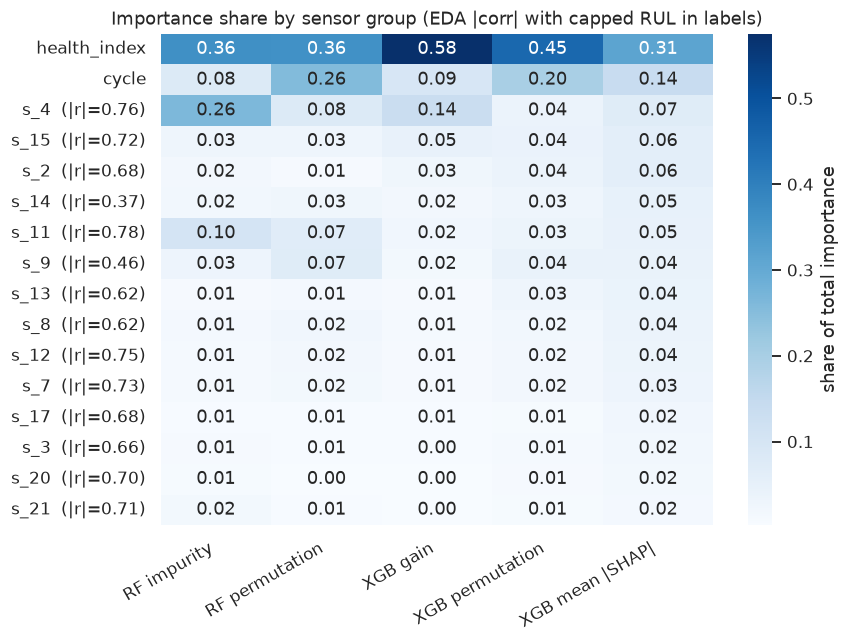

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(summary.drop(columns="EDA |corr| with capped RUL"), annot=True, fmt=".2f",
            cmap="Blues", cbar_kws={"label": "share of total importance"}, ax=ax)
ax.set_yticklabels([f"{g}  (|r|={eda_corr[g]:.2f})" if g in eda_corr else g
                    for g in summary.index], rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title("Importance share by sensor group (EDA |corr| with capped RUL in labels)")
fig.tight_layout()
save(fig, "methods_by_sensor")

In [13]:
# The health index is a linear model on regime-normalised sensors; its weights are comparable.
health_weights = pd.Series(full_scaler.health_model.coef_, index=USEFUL_SENSORS)
# Share of engines whose own correlation with RUL has the same sign as the pooled correlation.
per_engine = train.groupby("unit")[USEFUL_SENSORS + ["rul"]].corr()["rul"].unstack()[USEFUL_SENSORS]
pooled = train[USEFUL_SENSORS].corrwith(train["rul"])
pd.DataFrame({
    "health-index weight": health_weights,
    "pooled corr with capped RUL": pooled,
    "engines with same direction": (np.sign(per_engine) == np.sign(pooled)).mean(),
}).sort_values("health-index weight", key=abs, ascending=False)

,health-index weight,pooled corr with capped RUL,engines with same direction
s_11,-0.043,-0.775,1.00
s_9,-0.041,-0.462,0.71
s_12,0.038,0.749,1.00
s_4,-0.030,-0.757,1.00
s_7,0.027,0.733,1.00
s_14,-0.027,-0.370,0.60
s_21,0.020,0.707,1.00
s_20,0.019,0.705,1.00
s_15,-0.019,-0.721,1.00
s_17,-0.014,-0.681,1.00


The models do rely on the sensors that the exploratory analysis identified as degrading, but mostly through the health index, which is built from them. The health index and `cycle` together account for 45% of XGBoost's mean absolute SHAP value and 62 to 65% of each model's permutation importance, and the health index's largest weights are on `s_11`, `s_9`, `s_12`, `s_4`, and `s_7`. Among the individual sensor groups, `s_4`, `s_15`, and `s_2`, all of which rise towards failure, lead XGBoost's SHAP ranking, and `s_4` and `s_11` have the largest impurity importance in Random Forest.

There are two exceptions. `s_7` and `s_12` correlate strongly with RUL (0.73 and 0.75) but rank in the lower half for both models; their correlation with `s_4` and `s_11` is about 0.8 in absolute value, and they carry large health-index weights, so the trees gain little from them directly. `s_9` and `s_14` have the two weakest exploratory correlations and rank in the middle under impurity importance and SHAP. On held-out engines, however, `s_9` is XGBoost's most important single sensor (shuffling it raises RMSE by 1.05 cycles, ahead of `s_15` at 1.02 and `s_4` at 0.89) and Random Forest's second (1.45, behind `s_4` at 1.62). In 29% and 40% of engines respectively, the within-engine correlation of `s_9` and `s_14` with RUL has the opposite sign to the pooled one, which weakens the pooled correlation without removing the information the models use.

The reliance on `cycle` means the models partly predict from age. This works in FD001 because every engine starts in normal condition at cycle 1 and training lifetimes fall in a limited range (128 to 362 cycles), so age alone constrains the remaining life. It would transfer less well to engines with very different lifetimes or operating histories.

In [14]:
summary.join(ranks).to_csv(ROOT / "results" / "explain_by_sensor.csv")
permutation.to_csv(ROOT / "results" / "explain_permutation_folds.csv")
impurity.join(pd.Series(GROUPS, index=FEATURES, name="group")).join(coef).to_csv(
    ROOT / "results" / "explain_columns.csv")